# 03. PyTorch Computer Vision

[Computer vision](https://en.wikipedia.org/wiki/Computer_vision) is the art of teaching a computer to see. For example, it could involve building a model to classify whether a photo is of a cat or a dog ([binary classification](https://developers.google.com/machine-learning/glossary#binary-classification)).

Or whether a photo is of a cat, dog or chicken ([multi-class classification](https://developers.google.com/machine-learning/glossary#multi-class-classification)).

Or identifying where a car appears in a video frame ([object detection](https://en.wikipedia.org/wiki/Object_detection)). -> TIENE COORDENADAS Y LA ETIQUETA DEL OBJETO. TENSOR COORDENADA DE UN OBJETO DONDE CREE QUE ESTA A PARTIR DE LA ETIQUETA QUE LE DÍ

Or figuring out where different objects in an image can be separated ([panoptic segmentation](https://arxiv.org/abs/1801.00868)). -> TIENE UNA MÁSCARA PARA CADA OBJETO Y LA ETIQUETA CORRESPONDIENTE. TENSOR MÁSCARA DE CADA OBJETO DONDE CREE QUE ESTÁ A PARTIR DE LA ETIQUETA QUE LE DÍ. LA MASCARA LA DEFINE EL ÁREA DEL OBJETO EN LA IMAGEN.

![example computer vision problems](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-problems.png)
*Example computer vision problems for binary classification, multiclass classification, object detection and segmentation.*

We're going to apply the PyTorch Workflow we've been learning in the past couple of sections to computer vision.

![a PyTorch workflow with a computer vision focus](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-pytorch-computer-vision-workflow.png)

Specifically, we're going to cover:

| **Topic** | **Contents** |
| ----- | ----- |
| **0. Computer vision libraries in PyTorch** | PyTorch has a bunch of built-in helpful computer vision libraries, let's check them out.  |
| **1. Load data** | To practice computer vision, we'll start with some images of different pieces of clothing from [FashionMNIST](https://github.com/zalandoresearch/fashion-mnist). |
| **2. Prepare data** | We've got some images, let's load them in with a [PyTorch `DataLoader`](https://pytorch.org/docs/stable/data.html) so we can use them with our training loop. |
| **3. Model 0: Building a baseline model** | Here we'll create a multi-class classification model to learn patterns in the data, we'll also choose a **loss function**, **optimizer** and build a **training loop**. |
| **4. Making predictions and evaluating model 0** | Let's make some predictions with our baseline model and evaluate them. |
| **5. Setup device agnostic code for future models** | It's best practice to write device-agnostic code, so let's set it up. |
| **6. Model 1: Adding non-linearity** | Experimenting is a large part of machine learning, let's try and improve upon our baseline model by adding non-linear layers. |
| **7. Model 2: Convolutional Neural Network (CNN)** | Time to get computer vision specific and introduce the powerful convolutional neural network architecture. |
| **8. Comparing our models** | We've built three different models, let's compare them. |
| **9. Evaluating our best model** | Let's make some predictions on random images and evaluate our best model. |
| **10. Making a confusion matrix** | A confusion matrix is a great way to evaluate a classification model, let's see how we can make one. |
| **11. Saving and loading the best performing model** | Since we might want to use our model for later, let's save it and make sure it loads back in correctly. |

## 0. Computer vision libraries in PyTorch

Before we get started writing code, let's talk about some PyTorch computer vision libraries you should be aware of.

| PyTorch module | What does it do? |
| ----- | ----- |
| [`torchvision`](https://pytorch.org/vision/stable/index.html) | Contains datasets, model architectures and image transformations often used for computer vision problems. |
| [`torchvision.datasets`](https://pytorch.org/vision/stable/datasets.html) | Here you'll find many example computer vision datasets for a range of problems from image classification, object detection, image captioning, video classification and more. It also contains [a series of base classes for making custom datasets](https://pytorch.org/vision/stable/datasets.html#base-classes-for-custom-datasets). |
| [`torchvision.models`](https://pytorch.org/vision/stable/models.html) | This module contains well-performing and commonly used computer vision model architectures implemented in PyTorch, you can use these with your own problems. |
| [`torchvision.transforms`](https://pytorch.org/vision/stable/transforms.html) | Often images need to be transformed (turned into numbers/processed/augmented) before being used with a model, common image transformations are found here. |
| [`torch.utils.data.Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) | Base dataset class for PyTorch.  |
| [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html#module-torch.utils.data) | Creates a Python iterable over a dataset (created with `torch.utils.data.Dataset`). |

> **Note:** The `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes aren't only for computer vision in PyTorch, they are capable of dealing with many different types of data.

Now we've covered some of the most important PyTorch computer vision libraries, let's import the relevant dependencies.


In [2]:
# Import PyTorch
import torch
from torch import nn

# Import torchvision
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
# Note: your PyTorch version shouldn't be lower than 1.10.0 and torchvision version shouldn't be lower than 0.11
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

PyTorch version: 2.14.0
torchvision version: 0.29.0


## 1. Getting a dataset

To begin working on a computer vision problem, let's get a computer vision dataset.

We're going to start with FashionMNIST.

MNIST stands for Modified National Institute of Standards and Technology.

The [original MNIST dataset](https://en.wikipedia.org/wiki/MNIST_database) contains thousands of examples of handwritten digits (from 0 to 9) and was used to build computer vision models to identify numbers for postal services.

[FashionMNIST](https://github.com/zalandoresearch/fashion-mnist), made by Zalando Research, is a similar setup.

Except it contains grayscale images of 10 different kinds of clothing.

![example image of FashionMNIST](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-fashion-mnist-slide.png)
*`torchvision.datasets` contains a lot of example datasets you can use to practice writing computer vision code on. FashionMNIST is one of those datasets. And since it has 10 different image classes (different types of clothing), it's a multi-class classification problem.*

Later, we'll be building a computer vision neural network to identify the different styles of clothing in these images.

PyTorch has a bunch of common computer vision datasets stored in `torchvision.datasets`.

Including FashionMNIST in [`torchvision.datasets.FashionMNIST()`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html).

To download it, we provide the following parameters:
* `root: str` - which folder do you want to download the data to?
* `train: Bool` - do you want the training or test split?
* `download: Bool` - should the data be downloaded?
* `transform: torchvision.transforms` - what transformations would you like to do on the data?
* `target_transform` - you can transform the targets (labels) if you like too.

Many other datasets in `torchvision` have these parameter options.

In [3]:
# Setup training data
train_data = datasets.FashionMNIST(
    root="data", # where to download data to?
    train=True, # get training data
    download=True, # download data if it doesn't exist on disk
    transform=ToTensor(), # images come as PIL format, we want to turn into Torch tensors
    target_transform=None # you can transform labels as well
)

# Setup testing data
test_data = datasets.FashionMNIST(
    root="data",
    train=False, # get test data
    download=True,
    transform=ToTensor()
)

# ESTO YA NORMALIZA TMB DE 0 A 255 A 0 A 1

**PIL** stands for **Python Imaging Library** (now maintained as the **Pillow** fork). It is the standard library in Python for opening, manipulating, and saving many different image file formats (such as PNG, JPEG, BMP, etc.).

* **PIL Image Representation:** When you open an image using Pillow (or load a dataset like FashionMNIST without transformations), images are stored as objects of the `PIL.Image.Image` class.
* **Structure:** A PIL image holds metadata like width, height, and mode (such as `'L'` for 8-bit grayscale, or `'RGB'` for 3-channel color), alongside pixel data stored in memory in a format optimized for image processing library operations.
* **PyTorch Integration:** Deep learning models cannot process these Python objects directly. Therefore, we use `torchvision.transforms.ToTensor()` to automatically convert PIL images into PyTorch floats (`torch.Tensor`), scaling their pixel intensities from the range `[0, 255]` to `[0.0, 1.0]` at the same time.

Let's check out the first sample of the training data.

In [4]:
# See first training sample
image, label = train_data[0]
print(f"Image shape: {image.shape}") # ESCALA DE GRIS, 28 X 28
print(f"Label: {label}")
print(f"Min pixel value: {image.min()}")
print(f"Max pixel value: {image.max()}")

Image shape: torch.Size([1, 28, 28])
Label: 9
Min pixel value: 0.0
Max pixel value: 1.0


Visualizing the distribution of pixel values using a histogram is highly valuable in computer vision workflows for several key reasons:

1. **Understanding Data Scaling:** It lets us verify if our input features are correctly normalized or standardized. For example, raw image pixels typically range from `0` to `255`, but deep learning models often perform much better when inputs are scaled to `[0, 1]` or standardized to have a mean of `0` and variance of `1`.
2. **Identifying Background vs. Foreground:** In datasets like MNIST or FashionMNIST, a massive peak at `0.0` clearly shows how much of the image is occupied by black background pixels, while the remaining distribution indicates foreground object pixel intensities.
3. **Detecting Data Anomalies:** Extreme outliers, unexpected saturations (e.g., all pixels clumped at maximum/minimum bounds), or low contrast in images can be quickly identified and corrected during the preprocessing phase.


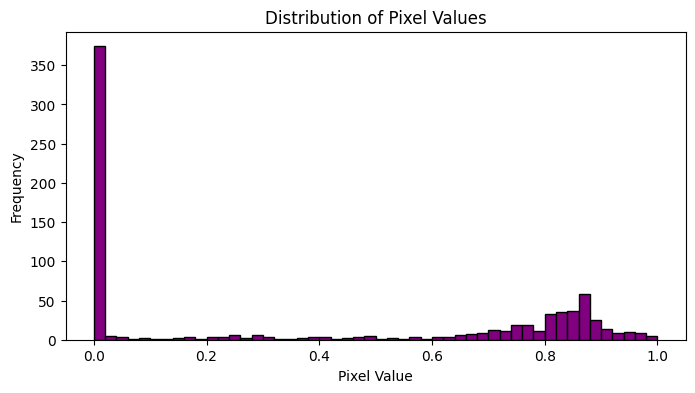

In [5]:
# Plot a histogram of pixel values
plt.figure(figsize=(8, 4))
plt.hist(image.numpy().flatten(), bins=50, color='purple', edgecolor='black')
plt.title("Distribution of Pixel Values")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

### 1.1 Input and output shapes of a computer vision model

We've got a big tensor of values (the image) leading to a single value for the target (the label).

Let's see the image shape.

In [6]:
# What's the shape of the image?
image.shape

torch.Size([1, 28, 28])

The shape of the image tensor is `[1, 28, 28]` or more specifically:

```
[color_channels=1, height=28, width=28]
```

Having `color_channels=1` means the image is grayscale.

![example input and output shapes of the fashionMNIST problem](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-input-and-output-shapes.png)
*Various problems will have various input and output shapes. But the premise remains: encode data into numbers, build a model to find patterns in those numbers, convert those patterns into something meaningful.*

If `color_channels=3`, the image comes in pixel values for red, green and blue (this is also known as the [RGB color model](https://en.wikipedia.org/wiki/RGB_color_model)).

The order of our current tensor is often referred to as `CHW` (Color Channels, Height, Width).

There's debate on whether images should be represented as `CHW` (color channels first) or `HWC` (color channels last).

> **Note:** You'll also see `NCHW` and `NHWC` formats where `N` stands for *number of images*. For example if you have a `batch_size=32`, your tensor shape may be `[32, 1, 28, 28]`. We'll cover batch sizes later.

PyTorch generally accepts `NCHW` (channels first) as the default for many operators.

However, PyTorch also explains that `NHWC` (channels last) performs better and is [considered best practice](https://pytorch.org/blog/tensor-memory-format-matters/#pytorch-best-practice).

For now, since our dataset and models are relatively small, this won't make too much of a difference.

In [7]:
# How many samples are there?
print(f"Train data: {len(train_data.data)}, Train labels: {len(train_data.targets)}\nTest size: {len(test_data.data)}, Test labels: {len(test_data.targets)}")

Train data: 60000, Train labels: 60000
Test size: 10000, Test labels: 10000


So we've got 60,000 training samples and 10,000 testing samples.

What classes are there? We can find these via the `.classes` attribute.

In [8]:
# See classes
class_names = train_data.classes
print(f"{[(i, c) for i, c in enumerate(class_names)]}")

[(0, 'T-shirt/top'), (1, 'Trouser'), (2, 'Pullover'), (3, 'Dress'), (4, 'Coat'), (5, 'Sandal'), (6, 'Shirt'), (7, 'Sneaker'), (8, 'Bag'), (9, 'Ankle boot')]


It looks like we're dealing with 10 different kinds of clothes. Because we're working with 10 different classes, it means our problem is **multi-class classification**.

### 1.2 Visualizing our data

When visualizing images using matplotlib, the images are usually presented in a blue-green-yellow color space called **Viridis**.

Viridis is the default color map in Matplotlib and is highly recommended for data visualization. It's a perceptually uniform colormap designed to represent data clearly, and accurately.

It is part of a family of four colormaps:

* viridis (blue-green-yellow)
* plasma (blue-purple-red-yellow)
* inferno (black-purple-red-yellow)
* magma (black-purple-red-white)

Image shape: torch.Size([1, 28, 28])
Squeezed Image shape: torch.Size([28, 28])


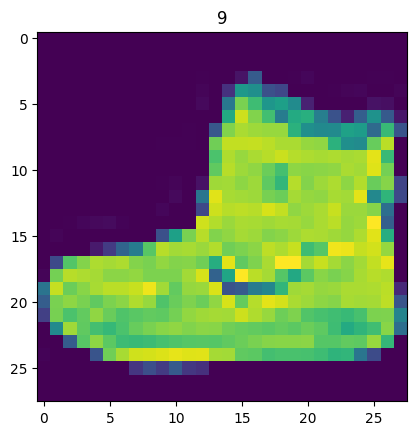

In [9]:
image, label = train_data[0]
print(f"Image shape: {image.shape}")
plt.imshow(image.squeeze(), cmap="viridis") # image shape is [1, 28, 28] (colour channels, height, width)
print(f"Squeezed Image shape: {image.squeeze().shape}")
plt.title(label);

We can turn the image into grayscale using the `cmap` parameter of `plt.imshow()`.

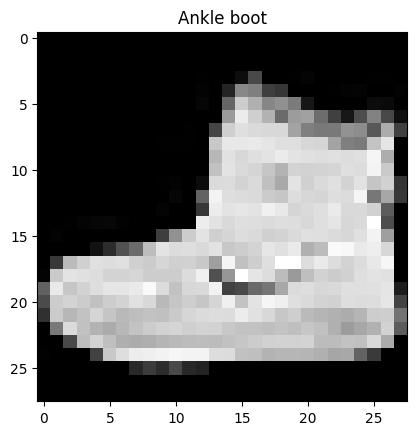

In [10]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label]);

Let's view a few more.

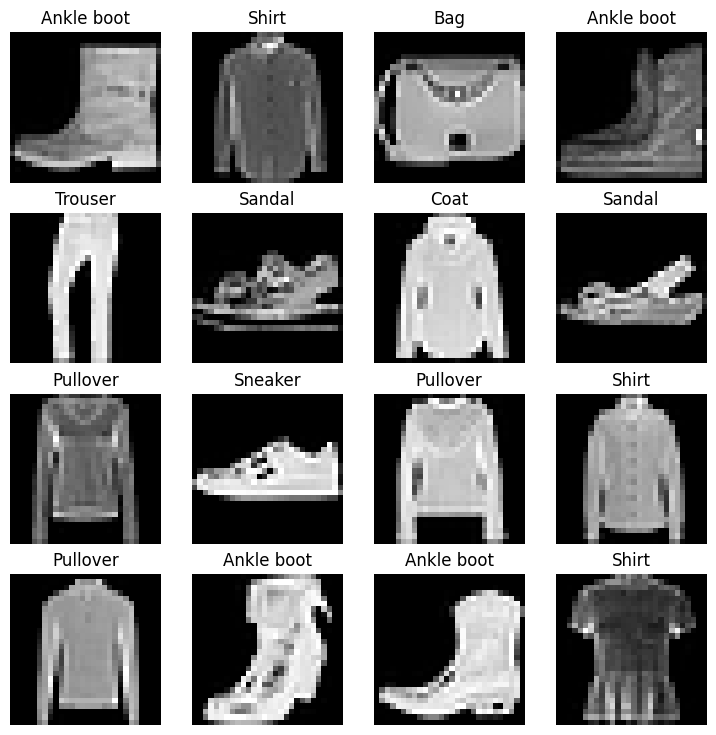

In [11]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False);

In essence, taking pixel values and building a model to find patterns in them to use on future pixel values.

## 2. Prepare DataLoader

The next step is to prepare it with a [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) or `DataLoader` for short.

The `DataLoader` helps load data into a model, for training and for inference.

It turns a large `Dataset` into a Python iterable of smaller chunks. These smaller chunks are called **batches** or **mini-batches** and can be set by the `batch_size` parameter.

Why do this?

Because it's more computationally efficient. In an ideal world you could do the forward pass and backward pass across all of your data at once.

But once you start using really large datasets, unless you've got infinite computing power, it's easier to break them up into batches.

It also gives your model more opportunities to improve.

With **mini-batches** (small portions of the data), gradient descent is performed more often per epoch (once per mini-batch rather than once per epoch).

[32 is a good place to start](https://twitter.com/ylecun/status/989610208497360896?s=20&t=N96J_jotN--PYuJk2WcjMw) for a fair amount of problems.

But since this is a value you can set (a **hyperparameter**) you can try all different kinds of values, though generally powers of 2 are used most often (e.g. 32, 64, 128, 256, 512).

![an example of what a batched dataset looks like](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-batching-fashionmnist.png)

*Batching FashionMNIST with a batch size of 32 and shuffle turned on. A similar batching process will occur for other datasets but will differ depending on the batch size.*

In [12]:
from torch.utils.data import DataLoader

# Setup the batch size hyperparameter
BATCH_SIZE = 32

# Turn datasets into iterables (batches)
train_dataloader = DataLoader(train_data, # dataset to turn into iterable
    batch_size=BATCH_SIZE, # how many samples per batch?
    shuffle=True # shuffle data every epoch?
)

test_dataloader = DataLoader(test_data,
    batch_size=BATCH_SIZE,
    shuffle=False # don't necessarily have to shuffle the testing data
)

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x11c61cad0>, <torch.utils.data.dataloader.DataLoader object at 0x11c9c6350>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [13]:
# Check out what's inside the training dataloader
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

And we can see that the data remains unchanged by checking a single sample.

Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


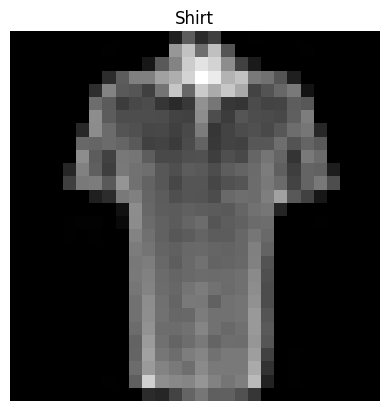

In [14]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("Off");
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

## 3. Model 0: Build a baseline model

Data loaded and prepared!

Time to build a **baseline model** by subclassing `nn.Module`.

A **baseline model** is one of the simplest models you can imagine.

You use the baseline as a starting point and try to improve upon it with subsequent, more complicated models.

Our baseline will consist of two [`nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layers.

We've done this in a previous section but there's going to be one slight difference.

Because we're working with image data, we're going to use a different layer to start things off.

And that's the [`nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html) layer.

`nn.Flatten()` compresses the dimensions of a tensor into a single vector.

This is easier to understand when you see it.

In [15]:
# Create a flatten layer
flatten_model = nn.Flatten() # all nn modules function as a model (can do a forward pass)

# Get a single sample
x = train_features_batch[0]

# Flatten the sample
output = flatten_model(x) # perform forward pass

# Print out what happened
print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} -> [color_channels, height*width]")

# Try uncommenting below and see what happens
#print(x)
#print(output)

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


The `nn.Flatten()` layer took our shape from `[color_channels, height, width]` to `[color_channels, height*width]`.

Why do this?

Because we've now turned our pixel data from height and width dimensions into one long **feature vector**.

And `nn.Linear()` layers like their inputs to be in the form of feature vectors.

Let's create our first model using `nn.Flatten()` as the first layer.

In [16]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(), # neural networks like their inputs in vector form
            nn.Linear(in_features=input_shape, out_features=hidden_units), # in_features = number of features in a data sample (784 pixels)
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )

    def forward(self, x):
        return self.layer_stack(x)

Wonderful!

We've got a baseline model class we can use, now let's instantiate a model.

We'll need to set the following parameters:
* `input_shape=784` - this is how many features you've got going in the model, in our case, it's one for every pixel in the target image (28 pixels high by 28 pixels wide = 784 features).
* `hidden_units=10` - number of units/neurons in the hidden layer(s), this number could be whatever you want but to keep the model small we'll start with `10`.
* `output_shape=len(class_names)` - since we're working with a multi-class classification problem, we need an output neuron per class in our dataset.

Let's create an instance of our model and send to the CPU for now (we'll run a small test for running `model_0` on CPU vs. a similar model on GPU soon).

In [17]:
torch.manual_seed(42)

# Need to setup model with input parameters
model_0 = FashionMNISTModelV0(input_shape=784, # one for every pixel (28x28)
    hidden_units=10, # how many units in the hidden layer
    output_shape=len(class_names) # one for every class
)
model_0.to("cpu") # keep model on CPU to begin with

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

### 3.1 Setup loss, optimizer and evaluation metrics

Since we're working on a classification problem, we will use various evaluation metrics from the [TorchMetrics package](https://torchmetrics.readthedocs.io/en/latest/).

In [18]:
!pip install torchmetrics

In [19]:
# Import accuracy metric
from torchmetrics.classification import Accuracy

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss() # this is also called "criterion"/"cost function" in some places
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 3.2 Creating a function to time our experiments

Loss function and optimizer ready!

It's time to start training a model.

But how about we do a little experiment while we train.

I mean, let's make a timing function to measure the time it takes our model to train on CPU versus using a GPU.

We'll train this model on the CPU but the next one on the GPU and see what happens.

Our timing function will import the [`timeit.default_timer()` function](https://docs.python.org/3/library/timeit.html#timeit.default_timer) from the Python [`timeit` module](https://docs.python.org/3/library/timeit.html).

In [20]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
    """Prints difference between start and end time.

    Args:
        start (float): Start time of computation (preferred in timeit format).
        end (float): End time of computation.
        device ([type], optional): Device that compute is running on. Defaults to None.

    Returns:
        float: time between start and end in seconds (higher is longer).
    """
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

### 3.3 Creating a training loop and training a model on batches of data

Beautiful!

Looks like we've got all of the pieces of the puzzle ready to go, a timer, a loss function, an optimizer, a model and most importantly, some data.

Let's now create a training loop and a testing loop to train and evaluate our model.

We'll be using the same steps as the previous notebook(s), though since our data is now in batch form, we'll add another loop to loop through our data batches.

Our data batches are contained within our `DataLoader`s, `train_dataloader` and `test_dataloader` for the training and test data splits respectively.

A batch is `BATCH_SIZE` samples of `X` (features) and `y` (labels), since we're using `BATCH_SIZE=32`, our batches have 32 samples of images and targets.

And since we're computing on batches of data, our loss and evaluation metrics will be calculated **per batch** rather than across the whole dataset.

This means we'll have to divide our loss and accuracy values by the number of batches in each dataset's respective dataloader.

Let's step through it:
1. Loop through epochs.
2. Loop through training batches, perform training steps, calculate the train loss *per batch*.
3. Loop through testing batches, perform testing steps, calculate the test loss *per batch*.
4. Print out what's happening.
5. Time it all (for fun).

A fair few steps but...

...if in doubt, code it out.

In [21]:
print(len(train_dataloader))

1875


In [22]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(42)
train_time_start_on_cpu = timer()

# Set the number of epochs (we'll keep this small for faster training times)
epochs = 3

metric = Accuracy(task="multiclass", num_classes=10)

# Create training and testing loop
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n-------")
    ### Training
    train_loss = 0
    # Add a loop to loop through training batches
    for batch, (X, y) in enumerate(train_dataloader):
        model_0.train()
        # 1. Forward pass
        y_pred = model_0(X)

        # 2. Calculate loss (per batch)
        loss = loss_fn(y_pred, y)
        metric.update(y_pred, y)
        train_loss += loss # accumulatively add up the loss per epoch

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Print out how many samples have been seen
        if batch % 400 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Divide total train loss by length of train dataloader (average loss per batch per epoch)
    train_loss /= len(train_dataloader)

    final_acc = metric.compute()

    print(f"Total Accuracy: {final_acc:.4f}")
    # Reset the metric (e.g., for the next epoch)
    metric.reset()

# Calculate training time
train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                           end=train_time_end_on_cpu,
                                           device=str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples


 33%|███▎      | 1/3 [00:01<00:02,  1.27s/it]

Looked at 51200/60000 samples
Total Accuracy: 0.7917
Epoch: 1
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples


 67%|██████▋   | 2/3 [00:02<00:01,  1.22s/it]

Looked at 51200/60000 samples
Total Accuracy: 0.8332
Epoch: 2
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples


100%|██████████| 3/3 [00:03<00:00,  1.21s/it]

Looked at 51200/60000 samples
Total Accuracy: 0.8409
Train time on cpu: 3.655 seconds


In [23]:
### Testing
# Setup variables for accumulatively adding up loss and accuracy
test_loss, test_acc = 0, 0
model_0.eval()

test_metric = Accuracy(task="multiclass", num_classes=10)

with torch.inference_mode():
    for X, y in test_dataloader:
        # 1. Forward pass
        test_pred = model_0(X)

        # 2. Calculate loss (accumulatively)
        test_loss += loss_fn(test_pred, y) # accumulatively add up the loss per epoch

        # 3. Calculate accuracy (preds need to be same as y_true)
        test_metric.update(test_pred, y)

    # Calculations on test metrics need to happen inside torch.inference_mode()
    # Divide total test loss by length of test dataloader (per batch)
    test_loss /= len(test_dataloader)

    test_acc = test_metric.compute()

## Print out what's happening
print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")


Train loss: 0.45325 | Test loss: 0.51088, Test acc: 0.82%



Nice! Looks like our baseline model did fairly well.

It didn't take too long to train either, even just on the CPU, I wonder if it'll speed up on the GPU?

Let's write some code to evaluate our model.

## 4. Make predictions and get Model 0 results

Since we're going to be building a few models, it's a good idea to write some code to evaluate them all in similar ways.

Namely, let's create a function that takes in a trained model, a `DataLoader`, a loss function and an accuracy function.

The function will use the model to make predictions on the data in the `DataLoader` and then we can evaluate those predictions using the loss function and accuracy function.

In [24]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module):
    """Returns a dictionary containing the results of model predicting on data_loader.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.

    Returns:
        (dict): Results of model making predictions on data_loader.
    """
    loss, acc = 0, 0
    metric = Accuracy(task="multiclass", num_classes=10)

    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            # Make predictions with the model
            y_pred = model(X)

            # Accumulate the loss and accuracy values per batch
            loss += loss_fn(y_pred, y)
            metric.update(y_pred, y)

        # Scale loss and acc to find the average loss/acc per batch
        loss /= len(data_loader)
        acc = metric.compute()

    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0, data_loader=test_dataloader, loss_fn=loss_fn)
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.5108762383460999,
 'model_acc': tensor(0.8238)}

Looking good!

We can use this dictionary to compare the baseline model results to other models later on.

## 5. Setup device agnostic-code (for using a GPU if there is one)
We've seen how long it takes to train ma PyTorch model on 60,000 samples on CPU.

> **Note:** Model training time is dependent on hardware used. Generally, more processors means faster training and smaller models on smaller datasets will often train faster than large models and large datasets.

Now let's setup some [device-agnostic code](https://pytorch.org/docs/stable/notes/cuda.html#best-practices) for our models and data to run on GPU if it's available.

If you're running this notebook on Google Colab, and you don't have a GPU turned on yet, it's now time to turn one on via `Runtime -> Change runtime type -> Hardware accelerator -> GPU`. If you do this, your runtime will likely reset and you'll have to run all of the cells above by going `Runtime -> Run before`.

In [25]:
# Setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

Beautiful!

Let's build another model.

## 6. Model 1: Building a better model with non-linearity

Seeing the data we've been working with, do you think it needs non-linear functions?

And remember, linear means straight and non-linear means non-straight.

Let's find out.

We'll do so by recreating a similar model to before, except this time we'll put non-linear functions (`nn.ReLU()`) in between each linear layer.

In [26]:
# Create a model with non-linear and linear layers
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(), # flatten inputs into single vector
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape),
            nn.ReLU()
        )

    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

That looks good.

Now let's instantiate it with the same settings we used before.

We'll need `input_shape=784` (equal to the number of features of our image data), `hidden_units=10` (starting small and the same as our baseline model) and `output_shape=len(class_names)` (one output unit per class).

> **Note:** Notice how we kept most of the settings of our model the same except for one change: adding non-linear layers. This is a standard practice for running a series of machine learning experiments, change one thing and see what happens, then do it again, again, again.

In [27]:
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=784, # number of input features
    hidden_units=100,
    output_shape=len(class_names) # number of output classes desired
).to(device) # send model to GPU if it's available
next(model_1.parameters()).device # check model device

device(type='cpu')

### 6.1 Setup loss, optimizer and evaluation metrics

As usual, we'll setup a loss function, an optimizer and an evaluation metric (we could do multiple evaluation metrics but we'll stick with accuracy for now).

In [28]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

### 6.2 Functionizing training and test loops

So far we've been writing train and test loops over and over.

Let's write them again but this time we'll put them in functions so they can be called again and again.

And because we're using device-agnostic code now, we'll be sure to call `.to(device)` on our feature (`X`) and target (`y`) tensors.

For the training loop we'll create a function called `train_step()` which takes in a model, a `DataLoader` a loss function and an optimizer.

The testing loop will be similar but it'll be called `test_step()` and it'll take in a model, a `DataLoader`, a loss function and an evaluation function.

> **Note:** Since these are functions, you can customize them in any way you like. What we're making here can be considered barebones training and testing functions for our specific classification use case.

In [29]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device = device):
    train_loss, train_acc = 0, 0
    metric = Accuracy(task="multiclass", num_classes=10).to(device)

    model.to(device)
    model.train()

    for batch, (X, y) in enumerate(data_loader):
        # Send data to GPU
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss
        metric.update(y_pred, y)

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

    # Calculate loss and accuracy per epoch and print out what's happening
    train_loss /= len(data_loader)
    train_acc = metric.compute()
    metric.reset()
    print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")

    # Return raw python floats instead of PyTorch Tensors
    return train_loss.item(), train_acc.item()

def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    test_metric = Accuracy(task="multiclass", num_classes=10).to(device)
    model.to(device)
    model.eval() # put model in eval mode

    # Turn on inference context manager
    with torch.inference_mode():
        for X, y in data_loader:
            # Send data to GPU
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y)
            test_metric.update(test_pred, y)

        # Adjust metrics and print out
        test_loss /= len(data_loader)
        test_acc = test_metric.compute()
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")

        # Return raw python floats instead of PyTorch Tensors
        return test_loss.item(), test_acc.item()

Woohoo!

Now we've got some functions for training and testing our model, let's run them.

We'll do so inside another loop for each epoch.

That way, for each epoch, we're going through a training step and a testing step.

> **Note:** You can customize how often you do a testing step. Sometimes people do them every five epochs or 10 epochs or in our case, every epoch.

Let's also time things to see how long our code takes to run on the GPU.

In [30]:
torch.manual_seed(42)

# Measure time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()

results = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

epochs = 5
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n---------")
    train_loss, train_acc = train_step(data_loader=train_dataloader,
        model=model_1,
        loss_fn=loss_fn,
        optimizer=optimizer
    )
    test_loss, test_acc = test_step(data_loader=test_dataloader,
        model=model_1,
        loss_fn=loss_fn
    )

    # Store clean Python float primitives directly
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0
---------


 20%|██        | 1/5 [00:01<00:05,  1.49s/it]

Train loss: 0.65766 | Train accuracy: 0.76%
Test loss: 0.45636 | Test accuracy: 0.83%

Epoch: 1
---------


 40%|████      | 2/5 [00:03<00:04,  1.51s/it]

...

Train loss: 0.36890 | Train accuracy: 0.86%
Test loss: 0.39596 | Test accuracy: 0.86%

Epoch: 3
---------


 80%|████████  | 4/5 [00:05<00:01,  1.47s/it]

Train loss: 0.34147 | Train accuracy: 0.87%
Test loss: 0.36783 | Test accuracy: 0.87%

Epoch: 4
---------


100%|██████████| 5/5 [00:07<00:00,  1.48s/it]

Train loss: 0.32146 | Train accuracy: 0.88%
Test loss: 0.37260 | Test accuracy: 0.87%

Train time on cpu: 7.383 seconds


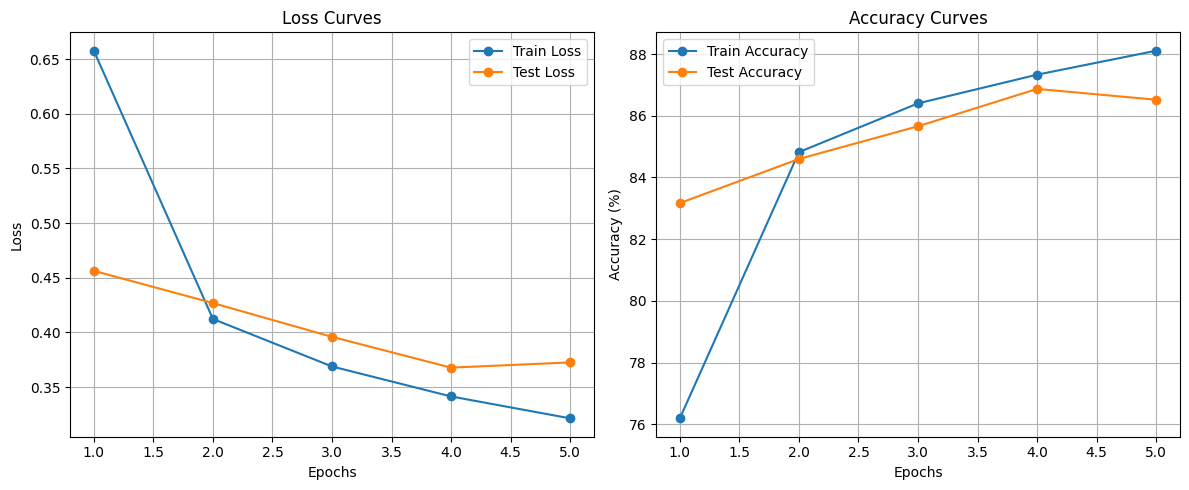

In [31]:
# --- Plotting Metrics ---
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

# Plot Loss Curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, results["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs_range, results["test_loss"], label="Test Loss", marker="o")
plt.title("Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Plot Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [acc * 100 for acc in results["train_acc"]], label="Train Accuracy", marker="o")
plt.plot(epochs_range, [acc * 100 for acc in results["test_acc"]], label="Test Accuracy", marker="o")
plt.title("Accuracy Curves")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# VISUALIZAR OVERFITTING Y UNDERFITTING
# TORCH METRICS GENERA UN TENSOR DE METRICA DE LOSS PARA CADA BATCH, USAMOS .ITEM PARA OBTENER EL VALOR ESCALAR PARA GRAFICARLO Y MOSTRARLO 



## Conclusiones con el gráfico
Con datos que no ha visto el modelo, empieza a subir el error, indicando que el modelo podría estar sobreajustado (overfitting) a los datos de entrenamiento. Por otro lado, si tanto el error de entrenamiento como el de prueba son altos (test oscila y entrenamiento se estanca, pero siempre en un mismo eje y, de repente baja), el modelo podría estar subajustado (underfitting).

Excellent!

Our model trained but the training time took longer?

> **Note:** The training time on CUDA vs CPU will depend largely on the quality of the CPU/GPU you're using. Read on for a more explained answer.

> **Question:** "I used a GPU but my model didn't train faster, why might that be?"
>
> **Answer:** Well, one reason could be because your dataset and model are both so small (like the dataset and model we're working with) the benefits of using a GPU are outweighed by the time it actually takes to transfer the data there.
>
> There's a small bottleneck between copying data from the CPU memory (default) to the GPU memory.
>
> So for smaller models and datasets, the CPU might actually be the optimal place to compute on.
>
> But for larger datasets and models, the speed of computing the GPU can offer usually far outweighs the cost of getting the data there.
>
> However, this is largely dependent on the hardware you're using. With practice, you will get used to where the best place to train your models is.

Let's evaluate our trained `model_1` using our `eval_model()` function and see how it went.

In [32]:
torch.manual_seed(42)

# Note: This will error due to `eval_model()` not using device agnostic code
model_1_results = eval_model(model=model_1,
    data_loader=test_dataloader,
    loss_fn=loss_fn)
model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.37260133028030396,
 'model_acc': tensor(0.8652)}

Oh no!

It looks like our `eval_model()` function errors out with:

> `RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_addmm)`

It's because we've setup our data and model to use device-agnostic code but not our evaluation function.

How about we fix that by passing a target `device` parameter to our `eval_model()` function?

Then we'll try calculating the results again.

In [33]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module):
    """Returns a dictionary containing the results of model predicting on data_loader.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.

    Returns:
        (dict): Results of model making predictions on data_loader.
    """
    loss, acc = 0, 0
    metric = Accuracy(task="multiclass", num_classes=10).to(device)

    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:

            # Send data to GPU
            X, y = X.to(device), y.to(device)

            # Make predictions with the model
            y_pred = model(X)

            # Accumulate the loss and accuracy values per batch
            loss += loss_fn(y_pred, y)
            metric.update(y_pred, y)

        # Scale loss and acc to find the average loss/acc per batch
        loss /= len(data_loader)
        acc = metric.compute()

    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0, data_loader=test_dataloader, loss_fn=loss_fn)
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.5108762383460999,
 'model_acc': tensor(0.8238)}

In [34]:
# Check baseline results
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.5108762383460999,
 'model_acc': tensor(0.8238)}

Woah, in this case, it looks like adding non-linearities to our model made it perform worse than the baseline.

That's a thing to note in machine learning, sometimes the thing you thought should work doesn't.

From the looks of things, it seems like our model is **overfitting** on the training data.

Overfitting means our model is learning the training data well but those patterns aren't generalizing to the testing data.

Two of the main ways to fix overfitting include:
1. Using a smaller or different model (some models fit certain kinds of data better than others).
2. Using a larger dataset (the more data, the more chance a model has to learn generalizable patterns).

There are more, but I'm going to leave that as a challenge for you to explore.

Try searching online, "ways to prevent overfitting in machine learning" and see what comes up.

## Make predictions and visualize results with Model 1

Let's write a helper function to make predictions with our trained model on a list of samples, then visualize them using Matplotlib alongside their true and predicted labels.

In [35]:
import random
torch.manual_seed(42)

def make_predictions(model: torch.nn.Module, data: list, device: torch.device = device):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample, label in data:
            # Prepare sample
            sample = torch.unsqueeze(sample, dim=0).to(device) # Add batch dimension and send to device

            # Forward pass (model outputs raw logits)
            pred_logit = model(sample)

            # Get prediction probability
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)

            # Get pred_probs off GPU for further use
            pred_probs.append(pred_prob.cpu())

    # Stack the pred_probs to turn list into a tensor
    return torch.stack(pred_probs)

To visually assess how well our model has learned, let's plot a few random predictions from the test set. Here is what the visualization script does:

1. **Random Sampling:** We randomly select $k=3$ images and labels from our test dataset.
2. **Inference Execution:** We pass these samples through our previously constructed helper function `make_predictions` using `model_1`.
3. **Probabilities to Classes:** We take the raw logit outputs from our model, apply a Softmax activation to convert them into probabilities, and extract the index of the highest probability using `.argmax(dim=1)` to find the predicted class.
4. **Adaptive Plotting:** We plot each image in a grid using Matplotlib. The plot title dynamically shows the model's prediction alongside the actual ground truth. If the prediction is correct, the title turns **green**; if incorrect, it turns **red** so we can spot classification errors instantly.

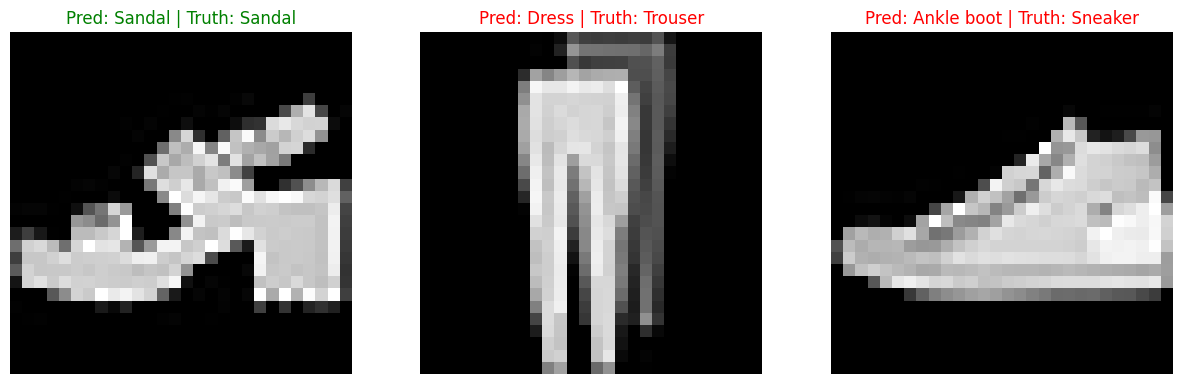

In [36]:
# Get random samples and labels from the test dataset
random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=3):
    test_samples.append(sample)
    test_labels.append(label)

# Make predictions
pred_probs = make_predictions(model=model_1, data=zip(test_samples, test_labels))

# Get predicted classes
pred_classes = pred_probs.argmax(dim=1)

# Plot predictions - modified to be as large as possible for the row
plt.figure(figsize=(15, 6))
nrows = 1
ncols = 3
for i, sample in enumerate(test_samples):
    # Create a subplot
    plt.subplot(nrows, ncols, i+1)

    # Plot target image
    plt.imshow(sample.squeeze(), cmap="gray")

    # Find the prediction label (in text form, e.g. "Sandal")
    pred_label = class_names[pred_classes[i]]

    # Get the truth label (in text form, e.g. "T-shirt")
    truth_label = class_names[test_labels[i]]

    # Create the title text
    title_text = f"Pred: {pred_label} | Truth: {truth_label}"

    # Check for equality and change title colour accordingly
    if pred_label == truth_label:
        plt.title(title_text, fontsize=12, color="g") # green text for correct predictions
    else:
        plt.title(title_text, fontsize=12, color="r") # red text for incorrect predictions

    plt.axis(False);

## Challenge

All of the exercises are focused on practicing the code in the sections above.

You should be able to complete them by referencing each section or by following the resource(s) linked.

All exercises should be completed using [device-agnostic code](https://pytorch.org/docs/stable/notes/cuda.html#device-agnostic-code).

1. **Load and Prepare Data**: Load the classic [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) (handwritten digits) and the [`torchvision.datasets.CIFAR10()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html) train and test datasets.
2. **Visualize Samples**: Visualize at least 5 different samples from both the MNIST and CIFAR-10 training datasets. Print their true labels.
3. **Prepare DataLoaders**: Turn both datasets into PyTorch dataloaders using `torch.utils.data.DataLoader` with a `batch_size=32`.
4. **Build Models**: Design and build different models capable of fitting the datasets.
5. **Train and Bench**: Train your models on both datasets using CPU and GPU (if available) and compare how long training takes on each device.
6. **Evaluate and Visualize Predictions**: Make predictions using your trained models. For each dataset, plot at least 9 random test images displaying the true target label alongside the model's predicted label to check its accuracy visually.

In [37]:
# 1. **Load and Prepare Data**: Load the classic [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) (handwritten digits) and the [`torchvision.datasets.CIFAR10()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html) train and test datasets.
# switch back to cpu
import torch
device = torch.device("cpu")

import matplotlib.pyplot as plt
import certifi
import ssl
import urllib.request
from torchvision import datasets
from torchvision.transforms import ToTensor

# Use a trusted CA bundle for HTTPS dataset downloads.
ssl_context = ssl.create_default_context(cafile=certifi.where())
urllib.request.install_opener(
    urllib.request.build_opener(urllib.request.HTTPSHandler(context=ssl_context))
)

'''MNIST'''
# Setup training data
train_data_mnist = datasets.MNIST(
    root="data", # where to download data to?
    train=True, # get training data
    download=True, # download data if it doesn't exist on disk
    transform=ToTensor(), # images come as PIL format, we want to turn them into Torch tensors
    target_transform=None # you can transform labels as well
)

# Setup testing data
test_data_mnist = datasets.MNIST(
    root="data",
    train=False, # get test data
    download=True,
    transform=ToTensor()
)

'''CIFAR10'''
# Setup training data
train_data_cifar10 = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

# Setup testing data
test_data_cifar10 = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape MNIST 0: torch.Size([1, 28, 28])
Label MNIST 0: 5 (5 - five)
Min pixel value MNIST 0: 0.0
Max pixel value MNIST 0: 1.0


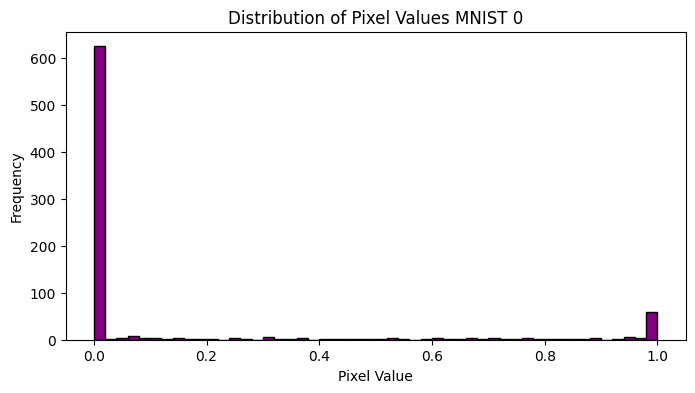

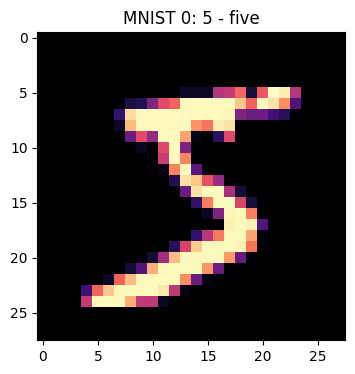

Image shape MNIST 1: torch.Size([1, 28, 28])
Label MNIST 1: 0 (0 - zero)
Min pixel value MNIST 1: 0.0
Max pixel value MNIST 1: 1.0


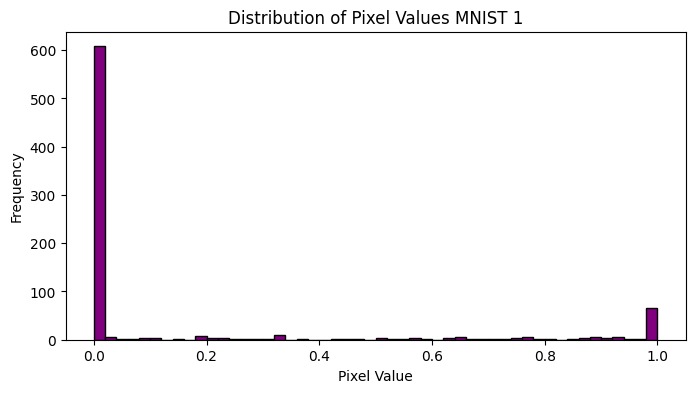

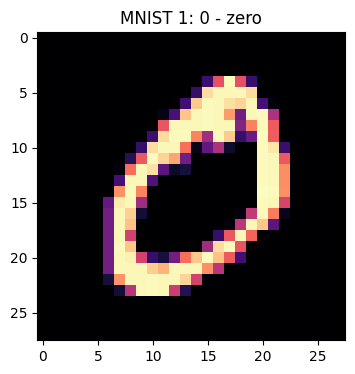

Image shape MNIST 2: torch.Size([1, 28, 28])
Label MNIST 2: 4 (4 - four)
Min pixel value MNIST 2: 0.0
Max pixel value MNIST 2: 1.0


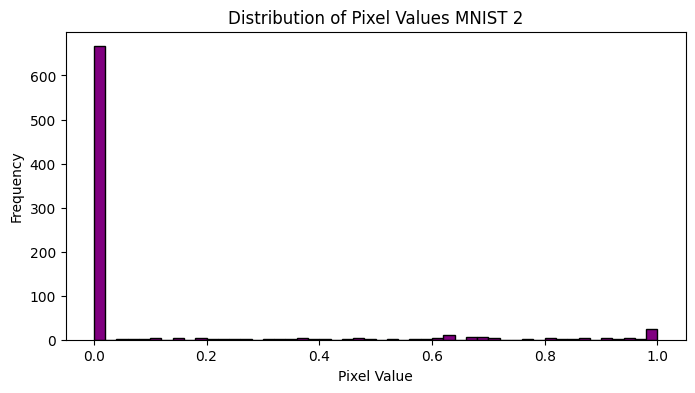

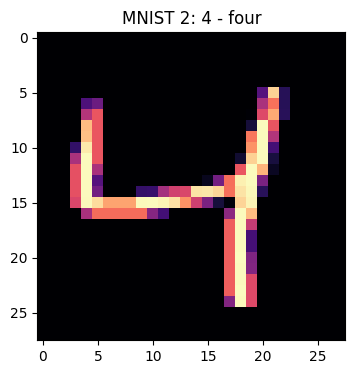

Image shape MNIST 3: torch.Size([1, 28, 28])
Label MNIST 3: 1 (1 - one)
Min pixel value MNIST 3: 0.0
Max pixel value MNIST 3: 1.0


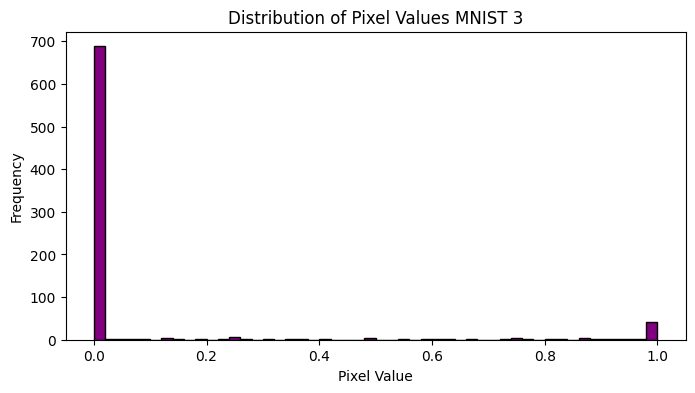

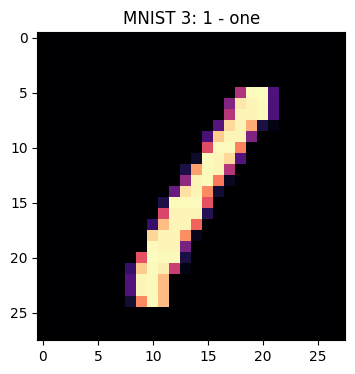

Image shape MNIST 4: torch.Size([1, 28, 28])
Label MNIST 4: 9 (9 - nine)
Min pixel value MNIST 4: 0.0
Max pixel value MNIST 4: 1.0


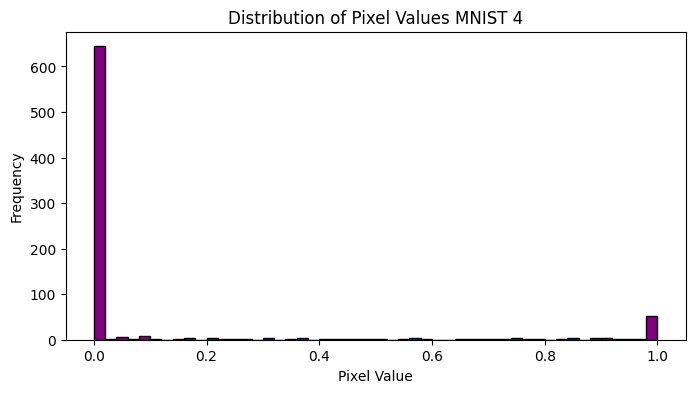

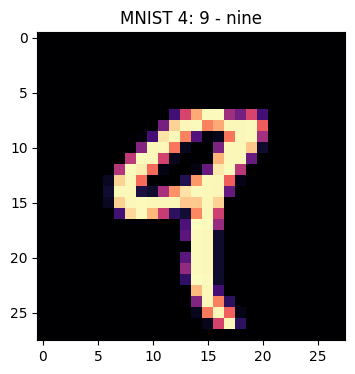

Train data MNIST: 60000, Test data MNIST: 10000
[(0, '0 - zero'), (1, '1 - one'), (2, '2 - two'), (3, '3 - three'), (4, '4 - four'), (5, '5 - five'), (6, '6 - six'), (7, '7 - seven'), (8, '8 - eight'), (9, '9 - nine')]
Image shape CIFAR-10 0: torch.Size([3, 32, 32])
Label CIFAR-10 0: 6 (frog)
Min pixel value CIFAR-10 0: 0.0
Max pixel value CIFAR-10 0: 1.0


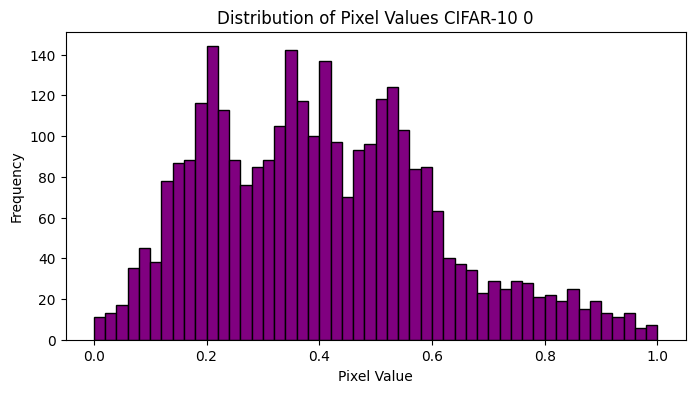

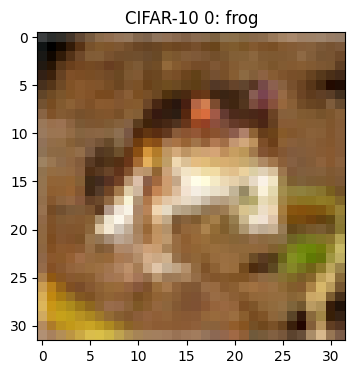

Image shape CIFAR-10 1: torch.Size([3, 32, 32])
Label CIFAR-10 1: 9 (truck)
Min pixel value CIFAR-10 1: 0.019607843831181526
Max pixel value CIFAR-10 1: 0.9960784316062927


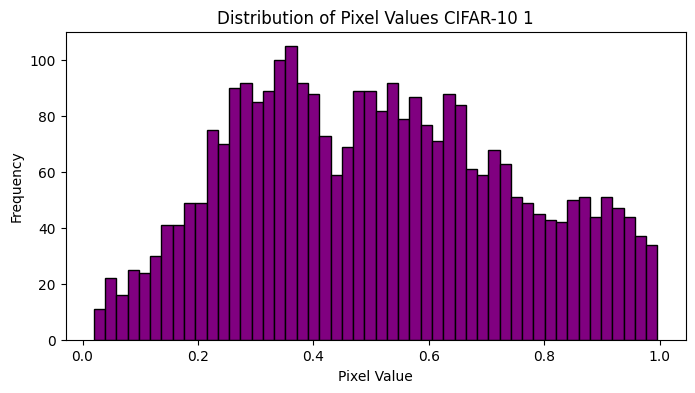

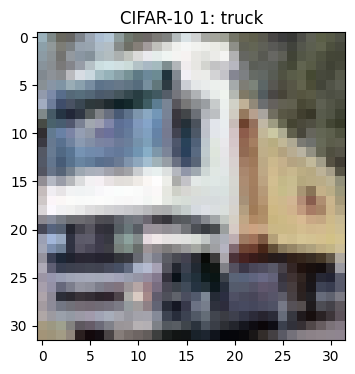

Image shape CIFAR-10 2: torch.Size([3, 32, 32])
Label CIFAR-10 2: 9 (truck)
Min pixel value CIFAR-10 2: 0.0784313753247261
Max pixel value CIFAR-10 2: 1.0


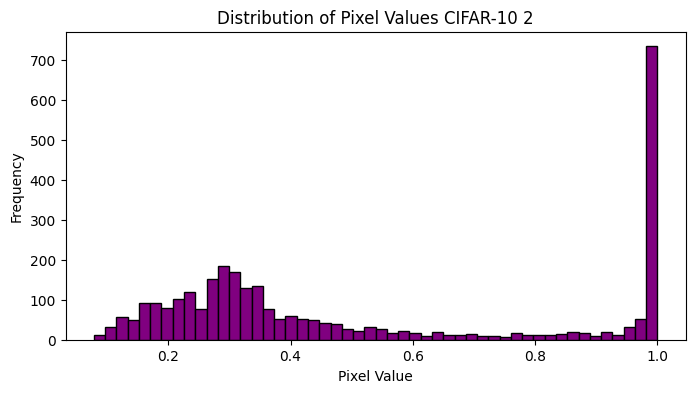

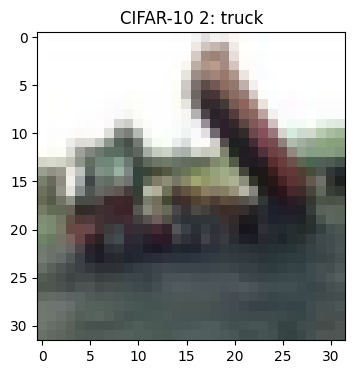

Image shape CIFAR-10 3: torch.Size([3, 32, 32])
Label CIFAR-10 3: 4 (deer)
Min pixel value CIFAR-10 3: 0.01568627543747425
Max pixel value CIFAR-10 3: 0.9176470637321472


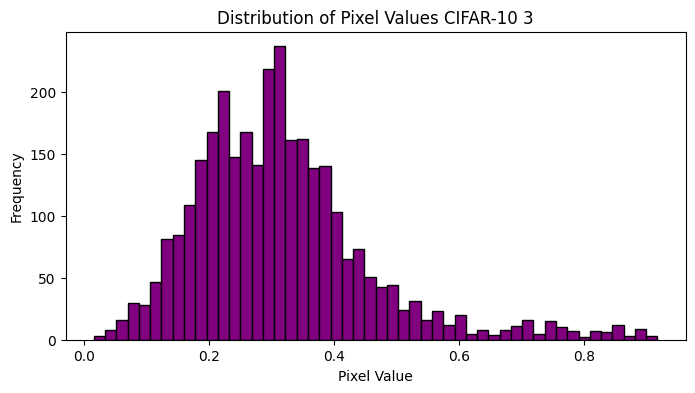

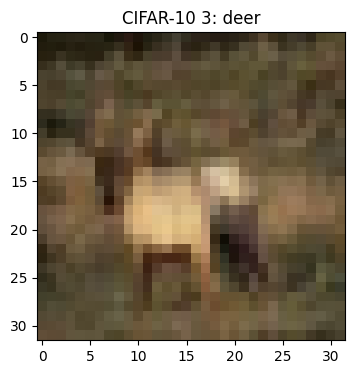

Image shape CIFAR-10 4: torch.Size([3, 32, 32])
Label CIFAR-10 4: 1 (automobile)
Min pixel value CIFAR-10 4: 0.0
Max pixel value CIFAR-10 4: 0.9960784316062927


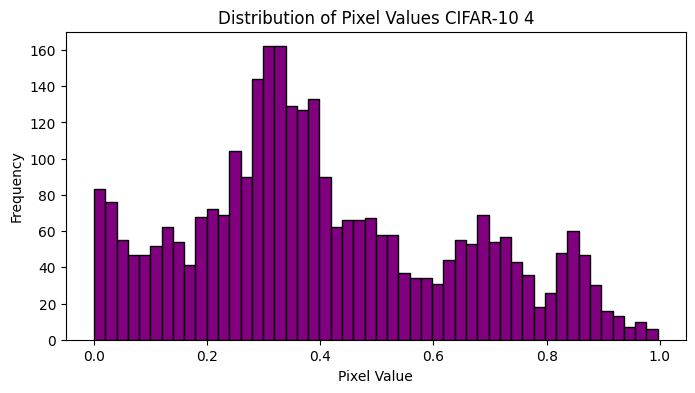

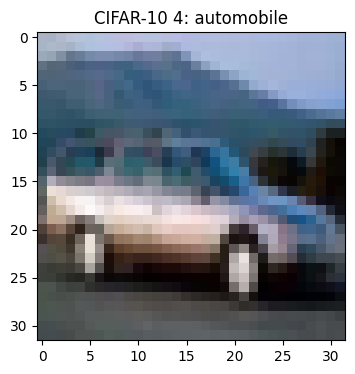

Train data CIFAR-10: 50000, Test data CIFAR-10: 10000
[(0, 'airplane'), (1, 'automobile'), (2, 'bird'), (3, 'cat'), (4, 'deer'), (5, 'dog'), (6, 'frog'), (7, 'horse'), (8, 'ship'), (9, 'truck')]


In [38]:
print(train_data_mnist.classes)
class_names_mnist = train_data_mnist.classes
print(train_data_cifar10.classes)
class_names_cifar10 = train_data_cifar10.classes

for sample_index in range(5):
    image_mnist, label = train_data_mnist[sample_index]
    print(f"Image shape MNIST {sample_index}: {image_mnist.shape}")
    print(f"Label MNIST {sample_index}: {label} ({class_names_mnist[label]})")
    print(f"Min pixel value MNIST {sample_index}: {image_mnist.min()}")
    print(f"Max pixel value MNIST {sample_index}: {image_mnist.max()}")
    plt.figure(figsize=(8, 4))
    plt.hist(image_mnist.numpy().flatten(), bins=50, color='purple', edgecolor='black')
    plt.title(f"Distribution of Pixel Values MNIST {sample_index}")
    plt.xlabel("Pixel Value")
    plt.ylabel("Frequency")
    plt.show()

    plt.figure(figsize=(4, 4))
    plt.imshow(image_mnist.squeeze(), cmap="magma")
    plt.title(f"MNIST {sample_index}: {class_names_mnist[label]}")
    plt.show()

print(f"Train data MNIST: {len(train_data_mnist)}, Test data MNIST: {len(test_data_mnist)}")
print(list(enumerate(class_names_mnist)))

for sample_index in range(5):
    image_cifar10, label = train_data_cifar10[sample_index]
    print(f"Image shape CIFAR-10 {sample_index}: {image_cifar10.shape}")
    print(f"Label CIFAR-10 {sample_index}: {label} ({class_names_cifar10[label]})")
    print(f"Min pixel value CIFAR-10 {sample_index}: {image_cifar10.min()}")
    print(f"Max pixel value CIFAR-10 {sample_index}: {image_cifar10.max()}")
    plt.figure(figsize=(8, 4))
    plt.hist(image_cifar10.numpy().flatten(), bins=50, color='purple', edgecolor='black')
    plt.title(f"Distribution of Pixel Values CIFAR-10 {sample_index}")
    plt.xlabel("Pixel Value")
    plt.ylabel("Frequency")
    plt.show()

    plt.figure(figsize=(4, 4))
    plt.imshow(train_data_cifar10.data[sample_index])
    plt.title(f"CIFAR-10 {sample_index}: {class_names_cifar10[label]}")
    plt.show()

print(f"Train data CIFAR-10: {len(train_data_cifar10)}, Test data CIFAR-10: {len(test_data_cifar10)}")
print(list(enumerate(class_names_cifar10)))

In [39]:
# 3. **Prepare DataLoaders**: Turn both datasets into PyTorch dataloaders using torch.utils.data.DataLoader with a batch_size=32.from torch.utils.data import DataLoader
# Setup the batch size hyperparameter
BATCH_SIZE = 32

# Turn datasets into iterables (batches)
train_dataloader_mnist = DataLoader(train_data_mnist, # dataset to turn into iterable
    batch_size=BATCH_SIZE, # how many samples per batch?
    shuffle=True # shuffle data every epoch?
)

test_dataloader_mnist = DataLoader(test_data_mnist,
    batch_size=BATCH_SIZE,
    shuffle=False # don't necessarily have to shuffle the testing data
)

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader_mnist, test_dataloader_mnist}")
print(f"Length of train dataloader: {len(train_dataloader_mnist)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader_mnist)} batches of {BATCH_SIZE}")

# Turn datasets into iterables (batches)
train_dataloader_cifar10 = DataLoader(train_data_cifar10, # dataset to turn into iterable
    batch_size=BATCH_SIZE, # how many samples per batch?
    shuffle=True # shuffle data every epoch?
)

test_dataloader_cifar10 = DataLoader(test_data_cifar10,
    batch_size=BATCH_SIZE,
    shuffle=False # don't necessarily have to shuffle the testing data
)

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader_cifar10, test_dataloader_cifar10}")
print(f"Length of train dataloader: {len(train_dataloader_cifar10)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader_cifar10)} batches of {BATCH_SIZE}")

# Check out what's inside the training dataloader
train_features_batch_mnist, train_labels_batch_mnist = next(iter(train_dataloader_mnist))
train_features_batch_mnist.shape, train_labels_batch_mnist.shape
train_features_batch_cifar10, train_labels_batch_cifar10 = next(iter(train_dataloader_cifar10))
train_features_batch_cifar10.shape, train_labels_batch_cifar10.shape



Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x1482f6990>, <torch.utils.data.dataloader.DataLoader object at 0x1286defd0>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32
Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x1286deb10>, <torch.utils.data.dataloader.DataLoader object at 0x128727bf0>)
Length of train dataloader: 1563 batches of 32
Length of test dataloader: 313 batches of 32


(torch.Size([32, 3, 32, 32]), torch.Size([32]))

In [40]:
# 4. **Build Models**: Design and build different models capable of fitting the datasets.

# Create a flatten layer
flatten_model = nn.Flatten() # all nn modules function as a model (can do a forward pass)
# Get a single sample
x_cifar10 = train_features_batch_cifar10[0]
x_mnist = train_features_batch_mnist[0]
# Flatten the sample
output_cifar10= flatten_model(x_cifar10) # perform forward pass
output_mnist = flatten_model(x_mnist) # perform forward pass
# Print out what happened
print(f"Shape before flattening: {x_cifar10.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output_cifar10.shape} -> [color_channels, height*width]")
print(f"Shape before flattening: {x_mnist.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output_mnist.shape} -> [color_channels, height*width]")

class ModelV0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(), # flatten inputs into single vector
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )
    
    def forward(self, x):
        return self.layer_stack(x)

# instances for both models 

torch.manual_seed(42)
# Need to setup model with input parameters
model_0_mnist = ModelV0(input_shape=784, # one for every pixel (28x28)
    hidden_units=10, # cachow many units in the hidden layer nums from 0 - 9, also 10 outputs
    output_shape=len(class_names) # one for every class
)
model_0_mnist.to("cpu") # keep model on CPU to begin with

torch.manual_seed(42)
# Need to setup model with input parameters
model_0_cifar10 = ModelV0(input_shape=3072, # one for every pixel (32x32x3)
    hidden_units=10, # cachow many units in the hidden layer, number of classes available: 10
    output_shape=len(class_names) # one for every class
)
model_0_cifar10.to("cpu") # keep model on CPU to begin with

# set uo loss, optimization and evaluation
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0_mnist.parameters(), lr=0.1)
optimizer_cifar10 = torch.optim.SGD(params=model_0_cifar10.parameters(), lr=0.1)

# set up training and test loops
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device = device):
    train_loss, train_acc = 0, 0
    metric = Accuracy(task="multiclass", num_classes=10).to(device)

    model.to(device)
    model.train()

    for batch, (X, y) in enumerate(data_loader):
        # Send data to GPU
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss
        metric.update(y_pred, y)

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

    # Calculate loss and accuracy per epoch and print out what's happening
    train_loss /= len(data_loader)
    train_acc = metric.compute()
    metric.reset()
    print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2%}")

    # Return raw python floats instead of PyTorch Tensors
    return train_loss.item(), train_acc.item()

def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    test_metric = Accuracy(task="multiclass", num_classes=10).to(device)
    model.to(device)
    model.eval() # put model in eval mode

    # Turn on inference context manager
    with torch.inference_mode():
        for X, y in data_loader:
            # Send data to GPU
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y)
            test_metric.update(test_pred, y)

        # Adjust metrics and print out
        test_loss /= len(data_loader)
        test_acc = test_metric.compute()
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2%}\n")

        # Return raw python floats instead of PyTorch Tensors
        return test_loss.item(), test_acc.item()


Shape before flattening: torch.Size([3, 32, 32]) -> [color_channels, height, width]
Shape after flattening: torch.Size([3, 1024]) -> [color_channels, height*width]
Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


In [41]:
from timeit import default_timer as timer
from torch.utils.data import DataLoader

cpu_device = torch.device("cpu")
gpu_device = torch.device("mps")

def benchmark_training(input_shape, class_names, train_loader, test_loader, target_device, num_epochs=20):
    torch.manual_seed(42)
    benchmark_model = ModelV0(
        input_shape=input_shape, hidden_units=128, output_shape=len(class_names)
    ).to(target_device)
    benchmark_optimizer = torch.optim.SGD(benchmark_model.parameters(), lr=0.01, momentum=0.9)
    benchmark_loss_fn = nn.CrossEntropyLoss()
    benchmark_loader = DataLoader(
        train_loader.dataset, batch_size=train_loader.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )
    train_eval_loader = DataLoader(
        train_loader.dataset, batch_size=train_loader.batch_size, shuffle=False,
        generator=torch.Generator().manual_seed(42)
    )
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    print(f"Model device: {next(benchmark_model.parameters()).device}")

    torch.mps.synchronize()
    start_time = timer()
    for epoch in range(num_epochs):
        print(f"Epoch: {epoch + 1}/{num_epochs}")
        print("Training (batch-time metrics):")
        train_step(
            model=benchmark_model, data_loader=benchmark_loader,
            loss_fn=benchmark_loss_fn, optimizer=benchmark_optimizer, device=target_device
        )
        print("End-of-epoch evaluation on the training set:")
        train_loss, train_acc = test_step(
            model=benchmark_model, data_loader=train_eval_loader,
            loss_fn=benchmark_loss_fn, device=target_device
        )
        print("End-of-epoch evaluation on the test set:")
        test_loss, test_acc = test_step(
            model=benchmark_model, data_loader=test_loader,
            loss_fn=benchmark_loss_fn, device=target_device
        )
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        print(f"End-of-epoch train accuracy: {train_acc:.2%} | Test accuracy: {test_acc:.2%}")
    torch.mps.synchronize()
    elapsed_time = timer() - start_time
    print(f"Training + evaluation on {target_device}: {elapsed_time:.3f} seconds")
    return benchmark_model, history, elapsed_time

epochs = 5
print("Starting MNIST CPU training...")
model_0_mnist, results_mnist_cpu, total_train_time_model_0_mnist = benchmark_training(
    784, class_names_mnist, train_dataloader_mnist, test_dataloader_mnist, cpu_device, epochs
)

print("Starting MNIST GPU training...")
model_0_mnist_gpu, results_mnist_gpu, total_train_time_model_0_mnist_gpu = benchmark_training(
    784, class_names_mnist, train_dataloader_mnist, test_dataloader_mnist, gpu_device, epochs
)

print("Starting CIFAR10 CPU training...")
model_0_cifar10, results_cifar10_cpu, total_train_time_model_0_cifar10 = benchmark_training(
    3072, class_names_cifar10, train_dataloader_cifar10, test_dataloader_cifar10, cpu_device, epochs
)

print("Starting CIFAR10 GPU training...")
model_0_cifar10_gpu, results_cifar10_gpu, total_train_time_model_0_cifar10_gpu = benchmark_training(
    3072, class_names_cifar10, train_dataloader_cifar10, test_dataloader_cifar10, gpu_device, epochs
)

Starting MNIST CPU training...
Model device: cpu
Epoch: 1/5
Training (batch-time metrics):
Train loss: 0.38492 | Train accuracy: 88.84%
End-of-epoch evaluation on the training set:
Test loss: 0.15354 | Test accuracy: 95.57%

End-of-epoch evaluation on the test set:
Test loss: 0.15465 | Test accuracy: 95.41%

End-of-epoch train accuracy: 95.57% | Test accuracy: 95.41%
Epoch: 2/5
Training (batch-time metrics):
Train loss: 0.13899 | Train accuracy: 95.84%
End-of-epoch evaluation on the training set:
Test loss: 0.09515 | Test accuracy: 97.13%

End-of-epoch evaluation on the test set:
Test loss: 0.10826 | Test accuracy: 96.46%

End-of-epoch train accuracy: 97.13% | Test accuracy: 96.46%
Epoch: 3/5
Training (batch-time metrics):
Train loss: 0.09356 | Train accuracy: 97.15%
End-of-epoch evaluation on the training set:
Test loss: 0.06489 | Test accuracy: 98.02%

End-of-epoch evaluation on the test set:
Test loss: 0.09283 | Test accuracy: 97.02%

End-of-epoch train accuracy: 98.02% | Test accur

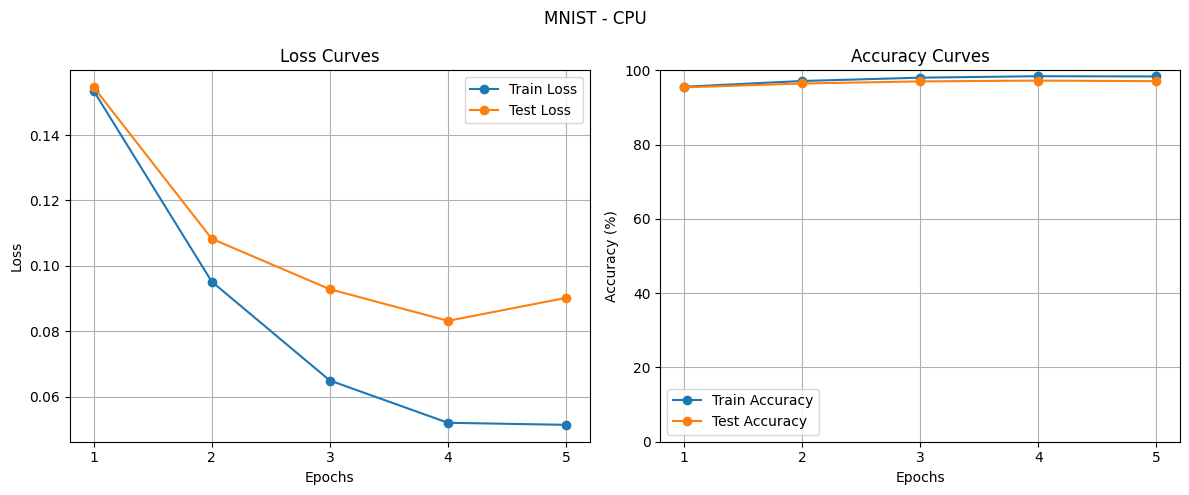

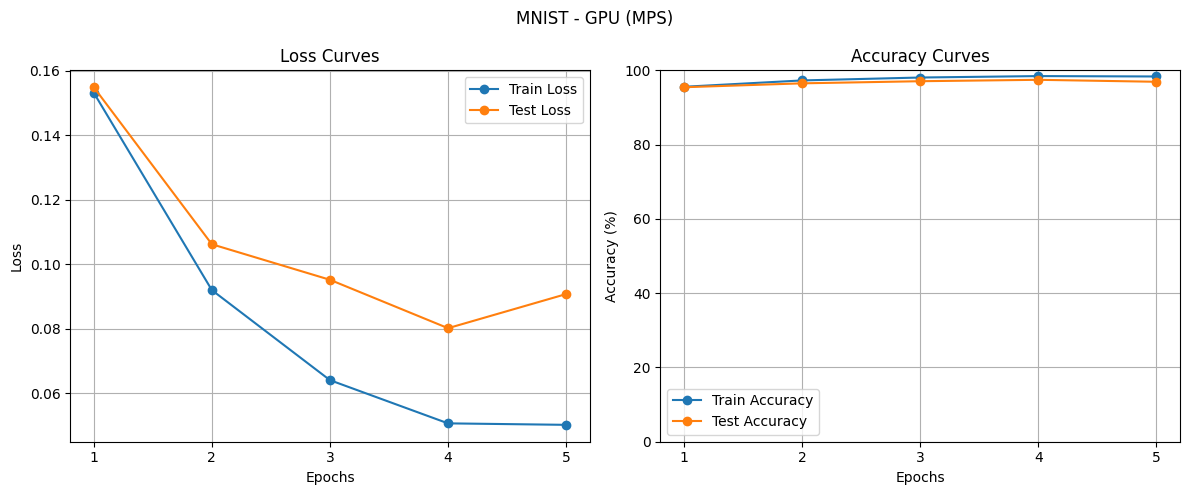

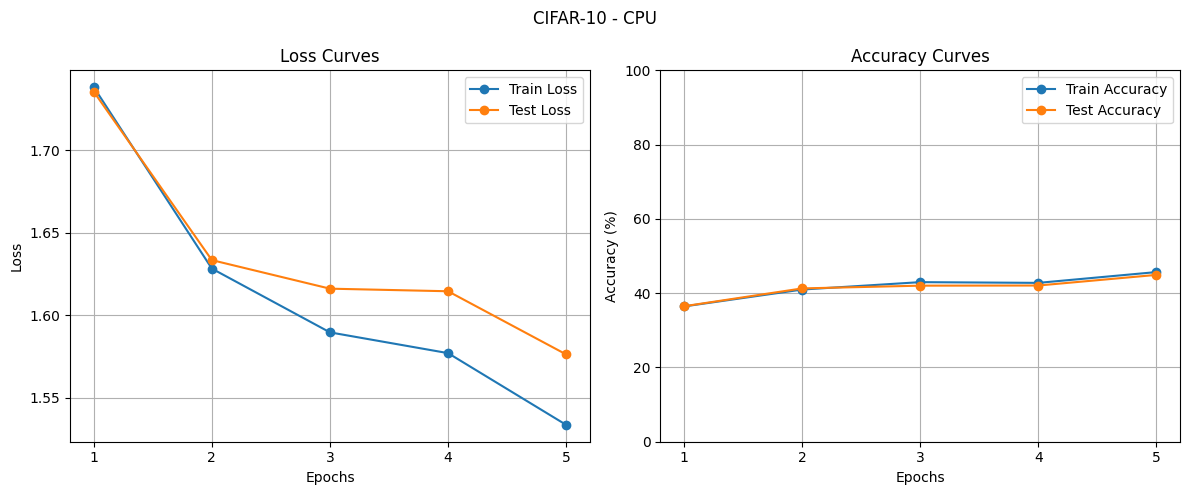

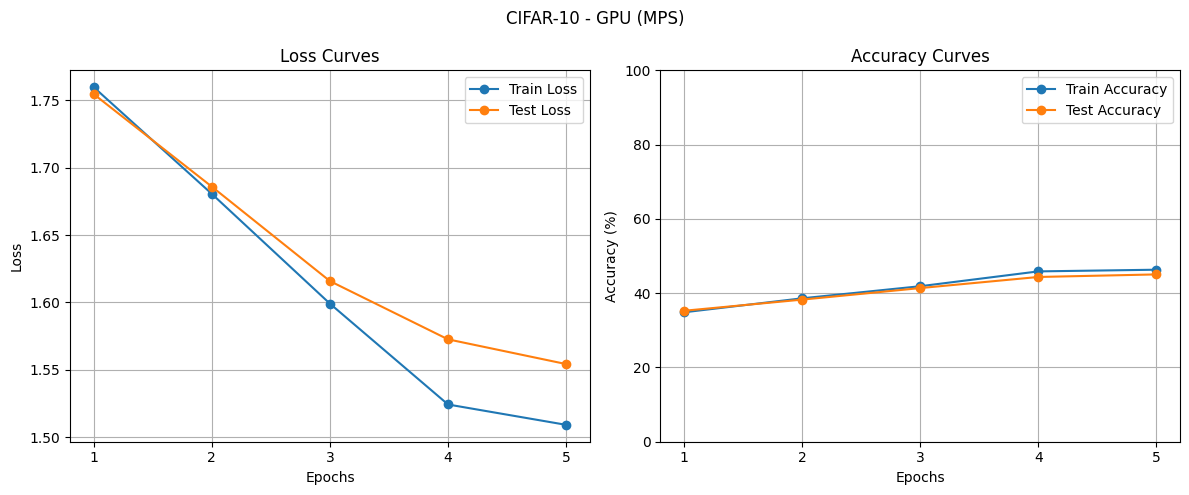

In [44]:
experiments = [
    ("MNIST - CPU", results_mnist_cpu),
    ("MNIST - GPU (MPS)", results_mnist_gpu),
    ("CIFAR-10 - CPU", results_cifar10_cpu),
    ("CIFAR-10 - GPU (MPS)", results_cifar10_gpu),
]

for experiment_name, history in experiments:
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(experiment_name)

    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
    axes[0].plot(epochs_range, history["test_loss"], label="Test Loss", marker="o")
    axes[0].set_title("Loss Curves")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")

    axes[1].plot(epochs_range, [acc * 100 for acc in history["train_acc"]], label="Train Accuracy", marker="o")
    axes[1].plot(epochs_range, [acc * 100 for acc in history["test_acc"]], label="Test Accuracy", marker="o")
    axes[1].set_title("Accuracy Curves")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_ylim(0, 100)

    for axis in axes:
        axis.set_xticks(epochs_range)
        axis.legend()
        axis.grid(True)

    fig.tight_layout()
    plt.show()

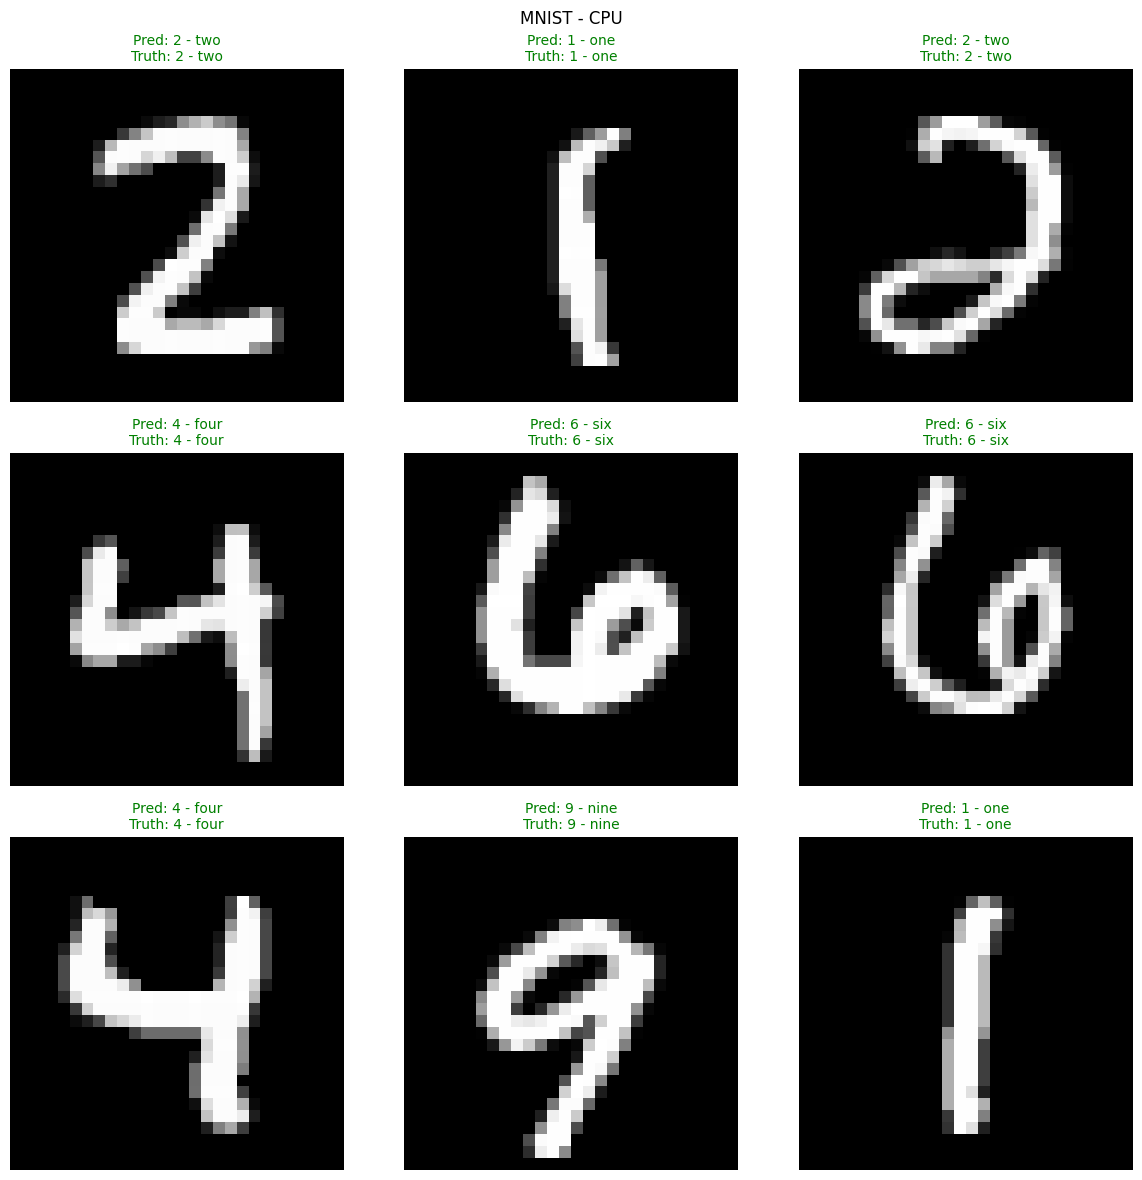

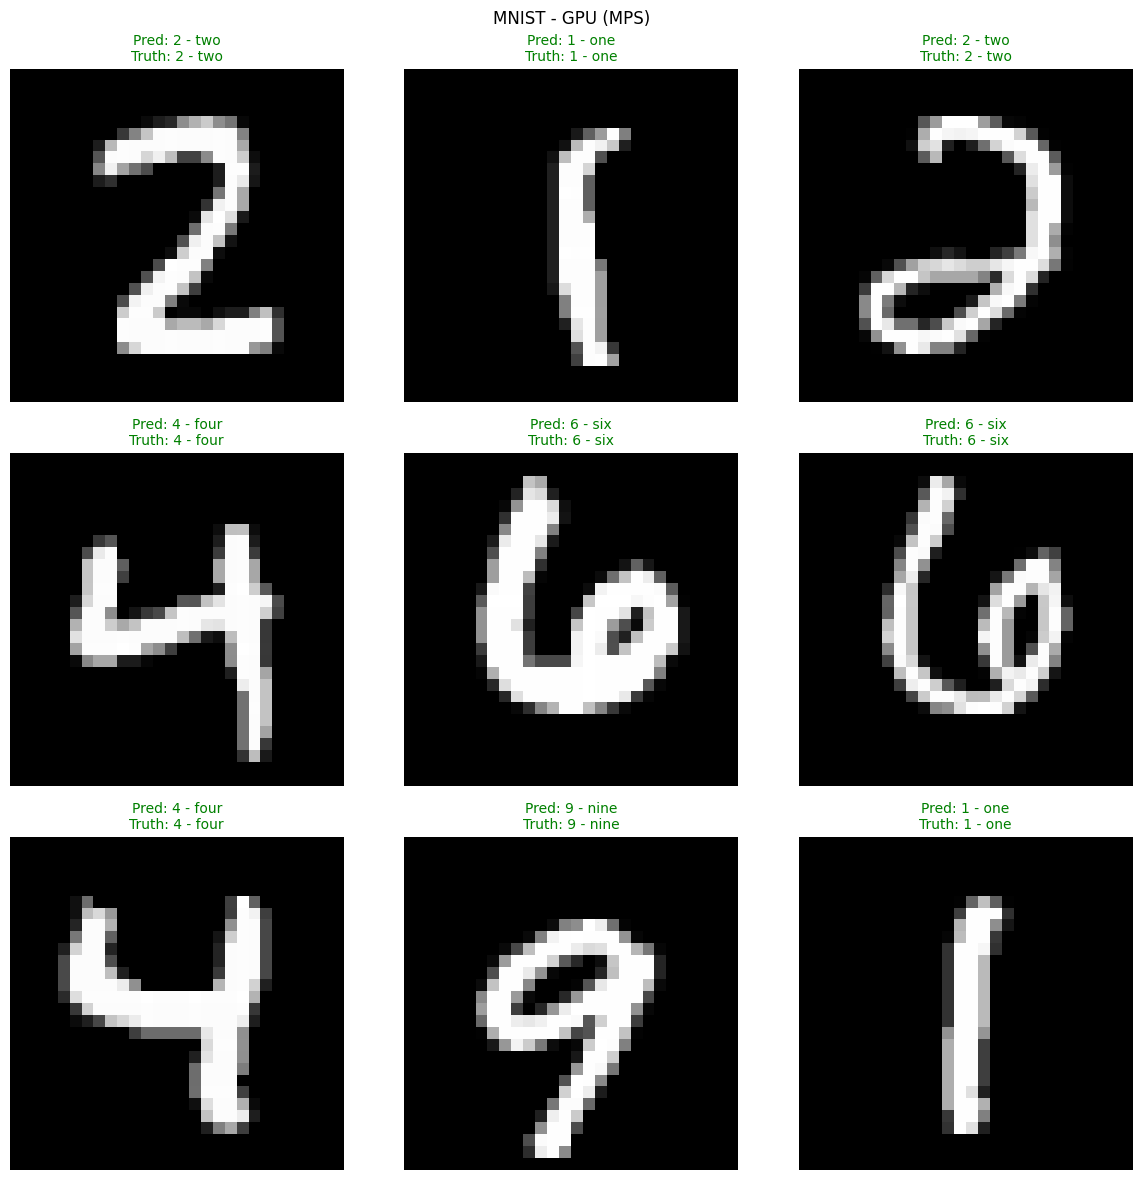

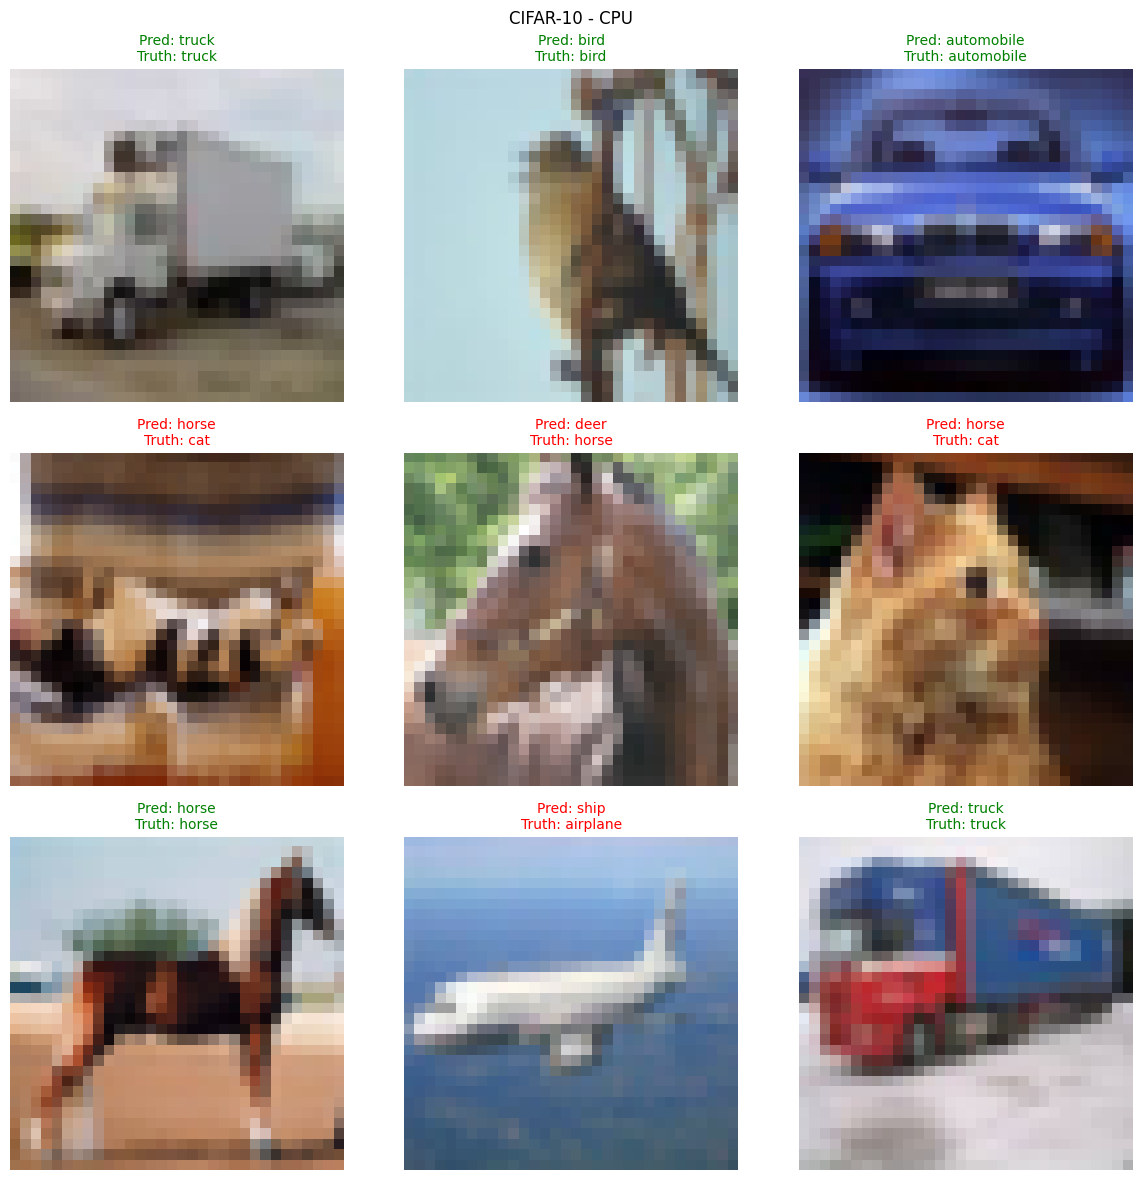

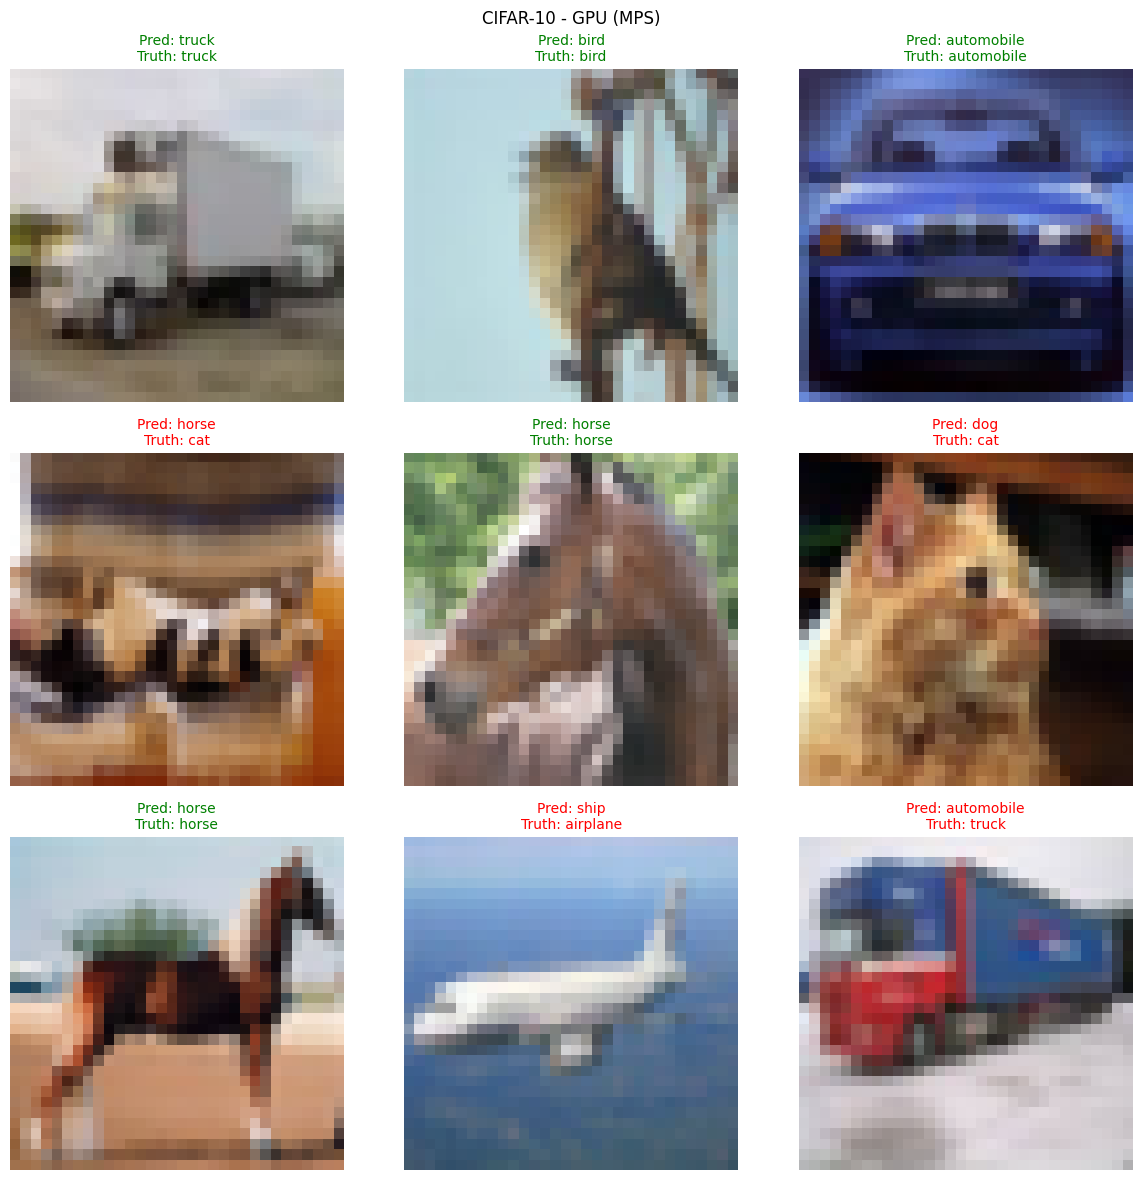

In [45]:
import random

prediction_datasets = [
    ("MNIST", test_data_mnist, class_names_mnist,
     [("CPU", model_0_mnist), ("GPU (MPS)", model_0_mnist_gpu)]),
    ("CIFAR-10", test_data_cifar10, class_names_cifar10,
     [("CPU", model_0_cifar10), ("GPU (MPS)", model_0_cifar10_gpu)]),
]

for dataset_name, test_dataset, dataset_classes, trained_models in prediction_datasets:
    sample_indices = random.Random(42).sample(range(len(test_dataset)), k=9)
    selected_samples = [test_dataset[index] for index in sample_indices]

    for device_name, trained_model in trained_models:
        model_device = next(trained_model.parameters()).device
        prediction_probs = make_predictions(
            model=trained_model, data=selected_samples, device=model_device
        )
        predicted_classes = prediction_probs.argmax(dim=1)

        prediction_fig, prediction_axes = plt.subplots(3, 3, figsize=(12, 12))
        prediction_fig.suptitle(f"{dataset_name} - {device_name}")

        for sample_number, (prediction_axis, (test_image, true_class)) in enumerate(
            zip(prediction_axes.flat, selected_samples)
        ):
            predicted_class = predicted_classes[sample_number].item()
            predicted_label = dataset_classes[predicted_class]
            true_label = dataset_classes[true_class]

            if test_image.shape[0] == 1:
                prediction_axis.imshow(test_image.squeeze(0).cpu(), cmap="gray")
            else:
                prediction_axis.imshow(test_image.permute(1, 2, 0).cpu())

            prediction_axis.set_title(
                f"Pred: {predicted_label}\nTruth: {true_label}",
                fontsize=10, color="g" if predicted_class == true_class else "r"
            )
            prediction_axis.axis("off")

        prediction_fig.tight_layout()
        plt.show()